

```
* Tentando melhorar a função de seleção de imagens do dataset...

ID                                  Nome
1PB64M-pLASGEqTdAo_MwDMV-r6anWMjP - caneca-1.jpeg
1jz1PsQNkF1HsBxaAgsMExpNSvNTh2pfv - caneca-2.jpeg
1rj4m7_6bYOWlTuesCDKc-zxkxnvQMxbi - caneca-3.jpeg
1Lb-gRa4ji1xIKIWF_KFF-_dOwmmlO70C - controle-1.jpeg
1yCyoMkgw8hEiVa2FF3nmLAtMDyRifndu - controle-2.jpeg
1l0LcAytHayglu23RZs4KjVTwaJE_gcly - controle-3.jpeg
15IoNG9z81iDLPW63oFW-PG6FIX1TC3Q- - isqueiro-1.jpeg
1BEdhnhscAUrTdO_lHf7wrg6CBnPCa0pA - isqueiro-2.jpeg
1z64LToeGXvmzVuIHexTizjyRog5Du3t4 - isqueiro-3.jpeg
1oNwhAVSsb6Pq8M9j2zVKHiBH1iJui5cB - mouse-1.jpeg
17U3UDwnZ9dP8r5MIsyE2ujXJ2H3nXIrJ - mouse-2.jpeg
1C-llHgcGvNXgzXa2v6jtZaIebxvqCT-g - mouse-3.jpeg

https://drive.google.com/drive/folders/1Qe_e2pp-Sbzc2WmwR1RbCk4o6SBKv0EA?usp=sharing
```



In [1]:
import gdown
import cv2


# Carrega uma imagem do dataset pela ID e nomeia ela na pasta.
def dataset(id="1PB64M-pLASGEqTdAo_MwDMV-r6anWMjP", name="caneca-1.jpeg"):
  url = f'https://drive.google.com/uc?id={id}'

  try:
    gdown.download(url, name, quiet=False) # Faz o download da imagem
    img = cv2.imread(name)                 # Lê a imagem e armazena em var
    img = np.array(img)                    # Converte em array numpy
    img = color.rgb2gray(img)              # Coloca em escala de cinza
    return img
  except Exception as e:
    print(f"Erro ao baixar ou processar a imagem: {e}")
    print("Retornando imagem padrão (camera) da skimage.")
    return img_as_float(data.camera())     # Retorna data.camera() se except

# Filtro da mediana

Nesta lição, vamos exercitar os filtros não-lineares mediana, dilatação e erosão.

A ideia é que você modifique estes exemplos para rodar com as suas imagens. Experimente outros kernels e elementos estruturantes.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, color, img_as_float
from skimage.util import img_as_ubyte
from skimage import data
from skimage.morphology import disk
from skimage.filters import median
from scipy.signal import convolve2d
from skimage.filters import gaussian


def show_images(imgs, titles=None, cmap=None, figsize=(14, 6)):
    """Utility to visualize one row of images."""
    n = len(imgs)
    if titles is None:
        titles = ["" for _ in range(n)]
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(imgs, titles), start=1):
        plt.subplot(1, n, i)
        if im.ndim == 2:
            plt.imshow(im, cmap=cmap if cmap else 'gray')
        else:
            plt.imshow(im)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [3]:
camera = dataset()

Downloading...
From: https://drive.google.com/uc?id=1PB64M-pLASGEqTdAo_MwDMV-r6anWMjP
To: /content/caneca-1.jpeg
100%|██████████| 157k/157k [00:00<00:00, 18.8MB/s]


## Filtro da mediana

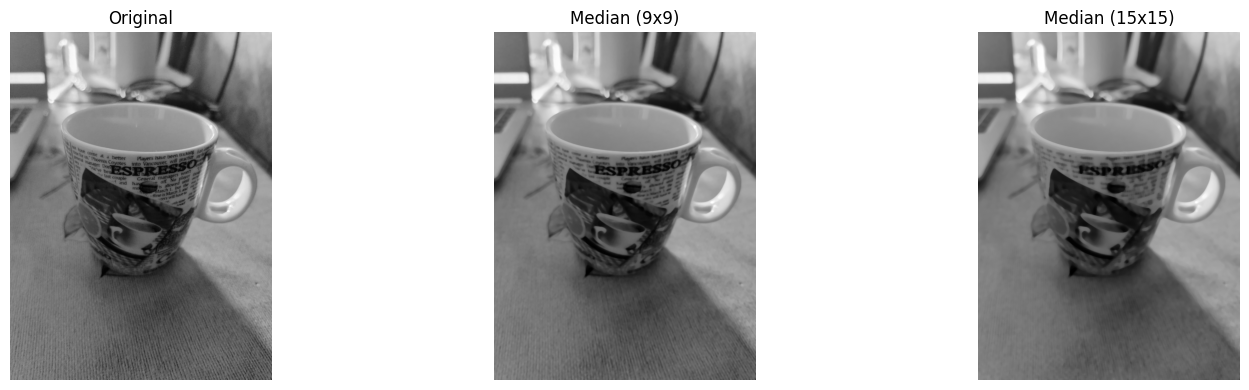

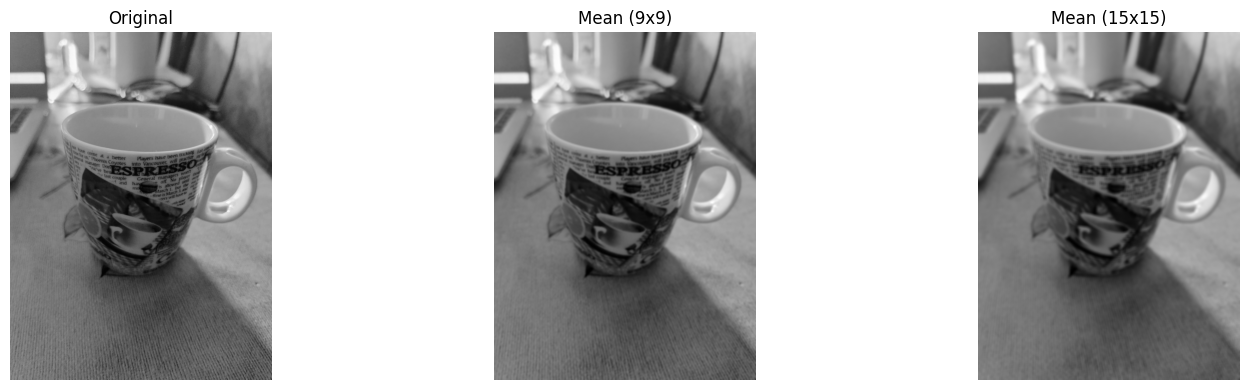

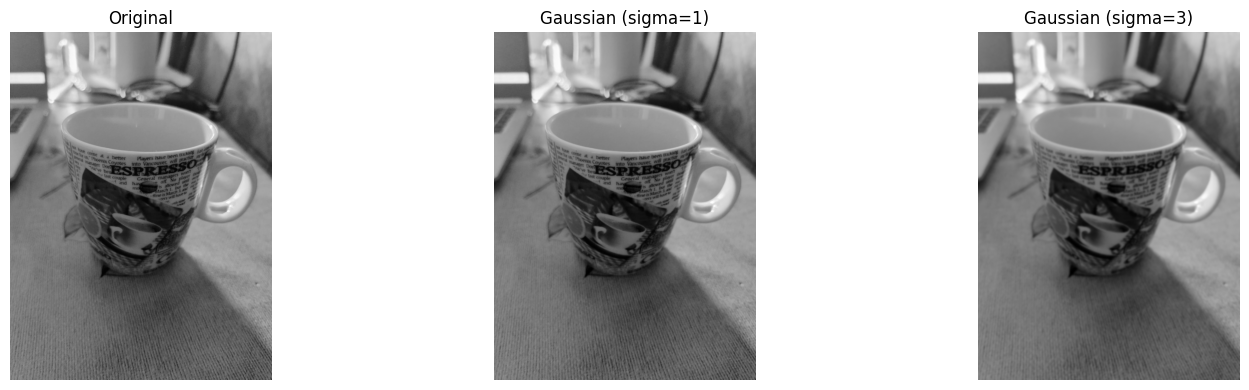

In [4]:
# Vamos pegar alguns kernels da aula
K9x9 = np.ones((9, 9), dtype=np.float64)

K15x15 = np.ones((15, 15), dtype=np.float64)

def medianImage(img, kernel):
    """Filtro da mediana de uma imagem em nivel de cinza."""
    res = median(img, kernel)
    return res

def meanImage(img, kernel, boundary='symm'):
    """Convolucao 2D de uma imagem em nivel de cinza."""
    res = convolve2d(img, kernel, mode='same', boundary=boundary)
    return res

# Aplicação e visualização do filtro de Mediana
resMedian9x9 = medianImage(camera, K9x9)
resMedian15x15 = medianImage(camera, K15x15)

show_images(
    [camera, resMedian9x9, resMedian15x15],
    titles=["Original", "Median (9x9)", "Median (15x15)"],
    cmap='gray',
    figsize=(16, 4)
)

# Aplicação e visualização do filtro de Média
resMean9x9 = meanImage(camera, K9x9)
resMean15x15 = meanImage(camera, K15x15)

show_images(
    [camera, resMean9x9, resMean15x15],
    titles=["Original", "Mean (9x9)", "Mean (15x15)"],
    cmap='gray',
    figsize=(16, 4)
)

# Aplicação e visualização do filtro de Gaussiano
resGaussian_sigma1 = gaussian(camera, sigma=1)
resGaussian_sigma3 = gaussian(camera, sigma=3)

show_images(
    [camera, resGaussian_sigma1, resGaussian_sigma3],
    titles=["Original", "Gaussian (sigma=1)", "Gaussian (sigma=3)"],
    cmap='gray',
    figsize=(16, 4)
)

### Filtro da mediana com loops

Complete o código com a função de mediana do numpy.

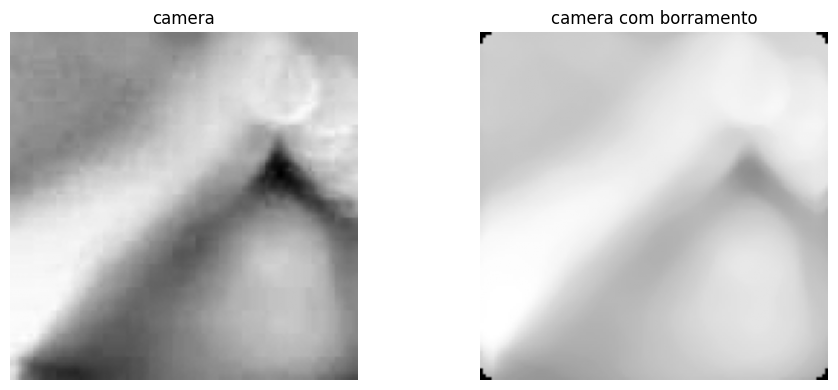

In [5]:
def medianWLoop(img, kernel):
    """Filtro da mediana (zero padding). O kernel precisa ter lados ímpares."""
    # Mudando os tipos para usar numpy
    img = img.astype(np.float64)
    k = kernel.astype(np.float64)
    # Tomando as dimensoes e verificando se o kernel tem as dimensoes corretas
    kh, kw = k.shape
    assert (kh % 2 == 1) and (kw % 2 == 1)
    # zero-padding
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    outImage = np.zeros_like(img, dtype=np.float64)

    H, W = img.shape
    for i in range(H):
        for j in range(W):
            patch = padded[i:i+kh, j:j+kw]
            outImage[i, j] = np.median(patch) # Função de borramento do numpy
    return outImage

cameraSmall = camera[200:320, 200:320]
resMedianCamera = medianWLoop(cameraSmall, K9x9)

show_images(
    [cameraSmall, resMedianCamera],
    titles=["camera", "camera com borramento"],
    cmap='gray',
    figsize=(10, 4)
)

## Exercícios extras

1. **Filtro da Mediana**
   - Experimente comparar com um filtro da média com kernel 5×5 e 3×3.
   - Experimente comparar com o filtro Gaussiano com a função `skimage.filters.gaussian`.

Como foi pedido em aula, eu aumentei o tamanho de cada kernel para melhor visualização em imagens de maior resolução.

O filtro de Mediana apresenta em seu desfoque uma maior definição de bordas do que o filtro de Média, que por sua definição as suaviza.

Já o filtro Gaussiano, parece ser um meio termo, sem tamanha definição nas bordas como o Mediano, mas sem eliminá-los gradativamente como o de Média.